In [1]:
import pylab
import imageio
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
from skimage import filters, measure
from skimage.io import imread
import cv2

import pandas as pd
from scipy import stats
!pip install statannotations

!pip install imageio-ffmpeg

Text(0.5, 0, 'Frame')

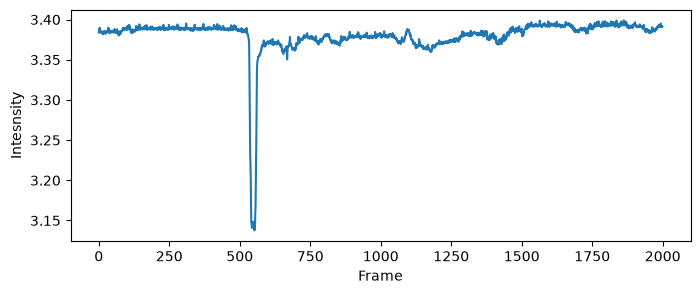

In [2]:
filename = 's13_OF_Cage6.mp4'
vid = imageio.get_reader(filename,  'ffmpeg')
nums = np.arange(0, 2000)
intensities = []
for num in nums:
    image = vid.get_data(num)
    frame_intensity = np.mean(image)
    intensities.append(frame_intensity)

#print(intensities)
#fig = pylab.figure()
#fig.suptitle('image #{}'.format(num), fontsize=20)
#pylab.imshow(image)
#pylab.show()


fh, ax = plt.subplots(1, 1, figsize=(8,3))
ax.plot(intensities)
ax.set_ylabel('Intesnsity')
ax.set_xlabel('Frame')

#find first frame thats below the baseline (1-500)


#np.argmin --> tells you at what index the minimum occurs
#min will be new start frame
#find out how many frames are in the video
#write that frame to a new video
#[400:800, 900:1275, :]


In [3]:
image.shape

(1080, 1920, 3)

In [4]:
# find whe the minimum of the index occurs
print(np.argmin(intensities))

# Make that minimum the new startframe
start_frame = np.argmin(intensities)

# determine the number of frames in the video
cap = cv2.VideoCapture('s13_OF_Cage6.mp4')
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

#print("Total frames:", total_frames)
final_frame = total_frames
print(final_frame)

# write the new frame as the begining of a new video, and the final frame as the last frame
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(fps)
print(width)
print(height)

frames = np.arange(start_frame, final_frame)
new_video = []
for frame in frames:



552
54689
14.693240421613348
1920
1080


In [5]:
import imageio.v3 as iio
!pip install imageio[pyav]

input_path = "s13_OF_Cage6.mp4"
output_path = "Documents/ABIO558_Repository_JS/Final_Project/8.20.26"

# Read source video metadata to preserve the original FPS
meta = iio.immeta(input_path, plugin="pyav")


zsh:1: no matches found: imageio[pyav]


ImportError: The `pyav` plugin is not installed. Use `pip install imageio[pyav]` to install it.

In [36]:
#Statistical Analysis
#import CSV from Simba
data = pd.read_csv('Final_Project_Simba_Data.csv', header=1, index_col=0)
data

,Center,Periphery,Peripher True,Genotype&Treatment
Animal,,,,
s10_OF_Cage4,453.142857,3847.785714,3394.642857,WT + Antibiotics
s11_OF_Cage4,562.428571,3831.857143,3269.428571,Het + Antibiotics
s12_OF_Cage4_,379.000000,3840.285714,3461.285714,WT + Antibiotics
s13_OF_Cage6,498.071429,3868.500000,3370.428571,WT + Control
s14_OF_Cages5&10,904.214286,3904.285714,3000.071429,Het + Antibiotics/Acetate
s15_OF_Cage6,364.785714,3858.285714,3493.500000,WT + Control
s16_OF_Cages5&10,251.928571,3890.285714,3638.357143,Het + Antibiotics/Acetate
s17_OF_Cage6,248.142857,3851.214286,3603.071429,WT + Control
s18_OF_Cage6,244.428571,3831.714286,3587.285714,Het + Control


In [37]:
#edit CSV to be in good format
averaged_times = data.groupby("Genotype&Treatment").agg('mean')
print(averaged_times)

                               Center    Periphery  Peripher True
Genotype&Treatment                                               
Het  + Antibiotics         562.428571  3831.857143    3269.428571
Het + Antibiotics/Acetate  602.642857  3889.714286    3287.071429
Het + Control              244.428571  3831.714286    3587.285714
KO + Control               300.833333  3840.142857    3539.309524
WT + Antibiotics           416.071429  3844.035714    3427.964286
WT + Control               370.333333  3859.333333    3489.000000


Text(0.5, 0, '')

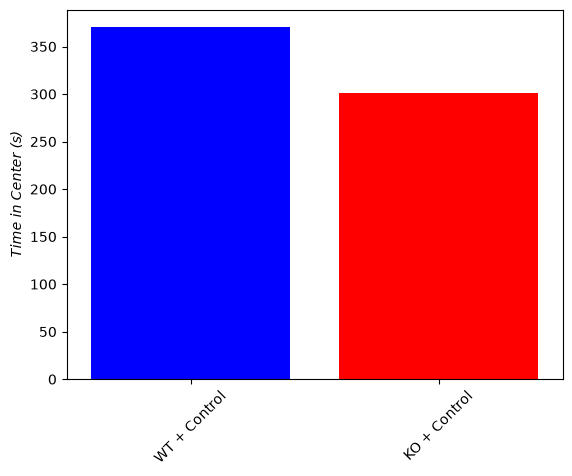

In [52]:
#make graph
order = ["WT + Control", "KO + Control"]

ax = sns.barplot(data=averaged_times, x="Genotype&Treatment", y="Center", order=order, errorbar="se", capsize=0.1)

colors = ["blue", "red"]
for bar, color in zip(ax.patches, colors): bar.set_facecolor(color)

plt.xticks(range(2), ["WT + Control", "KO + Control"], rotation=45)
plt.ylabel("Time in Center (s)", fontstyle='italic')
plt.xlabel("")


In [65]:
#run stats --> Mann-Whitney U
#The Mann-Whitney U test is a nonparametric test of the null hypothesis that the distribution underlying sample x is the same as the distribution underlying sample y. 
#It is often used as a test of difference in location between distributions.
WT_Con = [498.071429, 364.785714, 248.142857]
KO_Con = [458.928571,387.642857,55.928571]


result = stats.mannwhitneyu(WT_Con, KO_Con, alternative='two-sided', axis=0, method='auto')

print(f"U-statistic: {result.statistic}")
print(f"P-value: {result.pvalue:.4f}")

#U statistic: Reflects how often values in one group rank higher than values in the other. 
#Smaller U values (relative to sample sizes) indicate stronger separation between groups

U-statistic: 5.0
P-value: 1.0000
